In [2]:
import pickle
from pathlib import Path

import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
from jax import config
config.update("jax_enable_x64", True)

import seaborn as sns
import pandas as pd


In [3]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

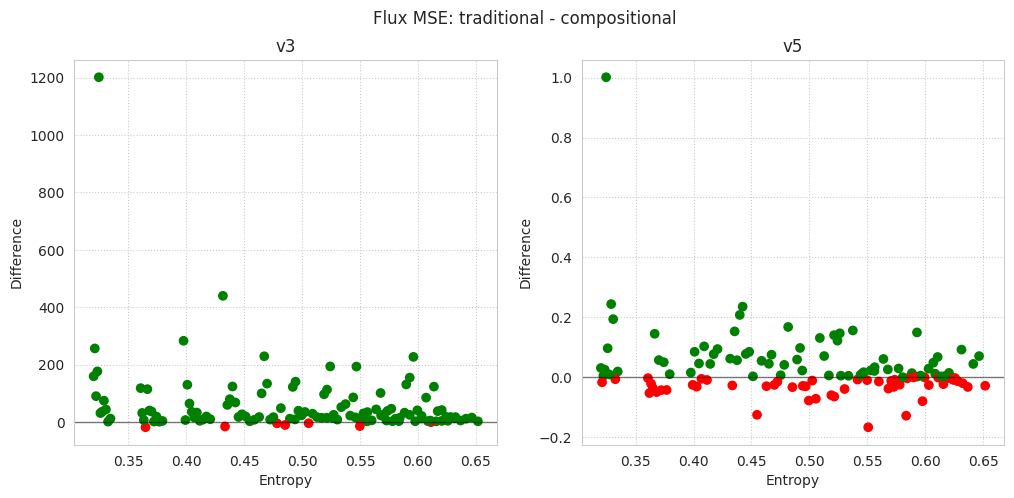

In [36]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
true_id_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
free_fluxes_toy = jnp.load(RESULTS_DIR_TOY / "free_fluxes.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [4, 5]])
resid_clr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["clr"][:, :, [4, 5]])
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [4, 5]])

mse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
mse_clr_toy = (resid_clr_toy ** 2).mean(axis=(0, 1))
mse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

entropies_toy = jnp.load(RESULTS_DIR_TOY / "entropies.npy")

f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

for i in range(2):
    y_values = diff_flux_toy[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_toy, y_values, c=colors)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="Entropy", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")
plt.show()


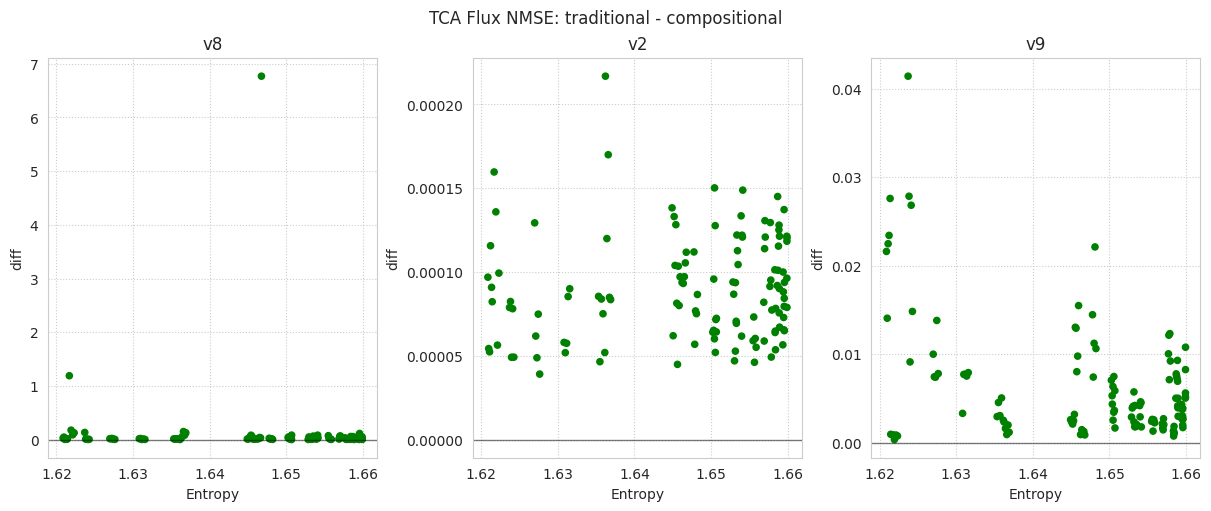

In [37]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
true_id_tca = np.load(RESULTS_DIR_TCA / "true_composition.npy", allow_pickle=True).item()
free_fluxes_tca = jnp.load(RESULTS_DIR_TCA / "free_fluxes.npy", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

resid_trad_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["trad"][:, :, :])
resid_clr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["clr"][:, :, :])
resid_ilr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["ilr"][:, :, :])

mse_trad_tca = (resid_trad_tca ** 2).mean(axis=(0, 1))
mse_clr_tca = (resid_clr_tca ** 2).mean(axis=(0, 1))
mse_ilr_tca = (resid_ilr_tca ** 2).mean(axis=(0, 1))


with open(RESULTS_DIR_TCA / "entropies.npy", "rb") as f:
    entropies_tca = pickle.load(f)
len(entropies_tca)

entropies_max = [max(idx.values()) for idx in entropies_tca]
diff_flux_tca= ((resid_trad_tca ** 2).mean(axis=1) - (resid_ilr_tca ** 2).mean(axis=1))

free_flux_numbers = jnp.array([8,2,9])

f, axes = plt.subplots(1, 3, figsize=[12, 5], layout= "constrained")
axes = axes.ravel()
point_size=20
for i in range(3):
    y_values = diff_flux_tca[:,i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_max, y_values, c=colors, s=point_size)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5, label="Reference flux")
    axes[i].set(xlabel="Entropy", ylabel="diff", title=f"v{free_flux_numbers[i]}")
f.suptitle("TCA Flux NMSE: traditional - compositional")

plt.show()

In [38]:
diff_flux_tca.shape

(125, 3)

In [39]:
diff_flux_toy.shape

(121, 2)

In [40]:
join =  jnp.concatenate([free_fluxes_toy[:,0], free_fluxes_toy[:,1]])

In [41]:
join

Array([25., 25., 25., 25., 25., 25., 25., 25., 25., 25., 25., 30., 30.,
       30., 30., 30., 30., 30., 30., 30., 30., 30., 35., 35., 35., 35.,
       35., 35., 35., 35., 35., 35., 35., 40., 40., 40., 40., 40., 40.,
       40., 40., 40., 40., 40., 45., 45., 45., 45., 45., 45., 45., 45.,
       45., 45., 45., 50., 50., 50., 50., 50., 50., 50., 50., 50., 50.,
       50., 55., 55., 55., 55., 55., 55., 55., 55., 55., 55., 55., 60.,
       60., 60., 60., 60., 60., 60., 60., 60., 60., 60., 65., 65., 65.,
       65., 65., 65., 65., 65., 65., 65., 65., 70., 70., 70., 70., 70.,
       70., 70., 70., 70., 70., 70., 75., 75., 75., 75., 75., 75., 75.,
       75., 75., 75., 75., 10., 12., 14., 16., 18., 20., 22., 24., 26.,
       28., 30., 10., 12., 14., 16., 18., 20., 22., 24., 26., 28., 30.,
       10., 12., 14., 16., 18., 20., 22., 24., 26., 28., 30., 10., 12.,
       14., 16., 18., 20., 22., 24., 26., 28., 30., 10., 12., 14., 16.,
       18., 20., 22., 24., 26., 28., 30., 10., 12., 14., 16., 18

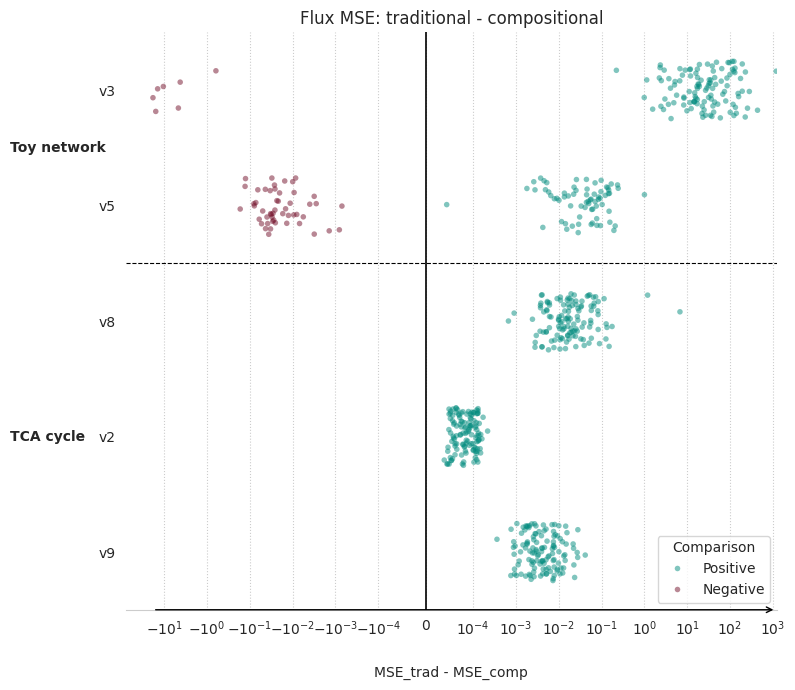

In [ ]:
df_toy = pd.DataFrame(diff_flux_toy, columns=['v3', 'v5']).melt(var_name='Version', value_name='Diff')
df_toy['Category'] = 'Toy network'

df_tca = pd.DataFrame(diff_flux_tca, columns=['v8', 'v2', 'v9']).melt(var_name='Version', value_name='Diff')
df_tca['Category'] = 'TCA cycle'

df = pd.concat([df_toy, df_tca], ignore_index=True)

df['ColorGroup'] = np.where(df['Diff'] < 0, 'Negative', 'Positive')

plt.figure(figsize=(8, 7))
sns.set_style("whitegrid", {'grid.linestyle': ':'})

ax = sns.stripplot(
    data=df, 
    x='Diff', 
    y='Version', 
    hue='ColorGroup', 
    palette={'Positive': '#038C7F', 'Negative': '#73102A'},
    alpha=0.5, 
    jitter=0.25,
    size=4
)

plt.axvline(0, color='black', linewidth=1.2)
plt.axhline(1.5, color='black', linestyle='--', linewidth=0.8) # Line between the two categories

# Labeling groups on the left
plt.text(-40000, 0.5, 'Toy network', fontweight='bold', ha='left', va='center')
plt.text(-40000, 3.0, 'TCA cycle', fontweight='bold', ha='left', va='center')

# Stylized X-axis (Arrow)
ax.spines['bottom'].set_position(('data', 4.5))
ax.spines[['top', 'right', 'left']].set_visible(False)
plt.annotate('', xy=(max(df['Diff'])+0.1, 4.5), xytext=(min(df['Diff'])-0.1, 4.5),
             arrowprops=dict(arrowstyle="->", color='black'))
ax.set_xscale("symlog", linthresh=1e-4)
plt.xlabel('MSE_trad - MSE_comp', labelpad=20)
plt.ylabel('')
# plt.xticks([0])
# plt.xlim(-0.1, 3)

plt.legend(title='Comparison', loc='lower right')
plt.title("Flux MSE: traditional - compositional")
plt.tight_layout()
plt.show()

Try make the y-axis ordered 


In [9]:
# diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))
diff_trad = (resid_trad_toy ** 2).mean(axis=1)
diff_comp = (resid_ilr_toy ** 2).mean(axis=1)

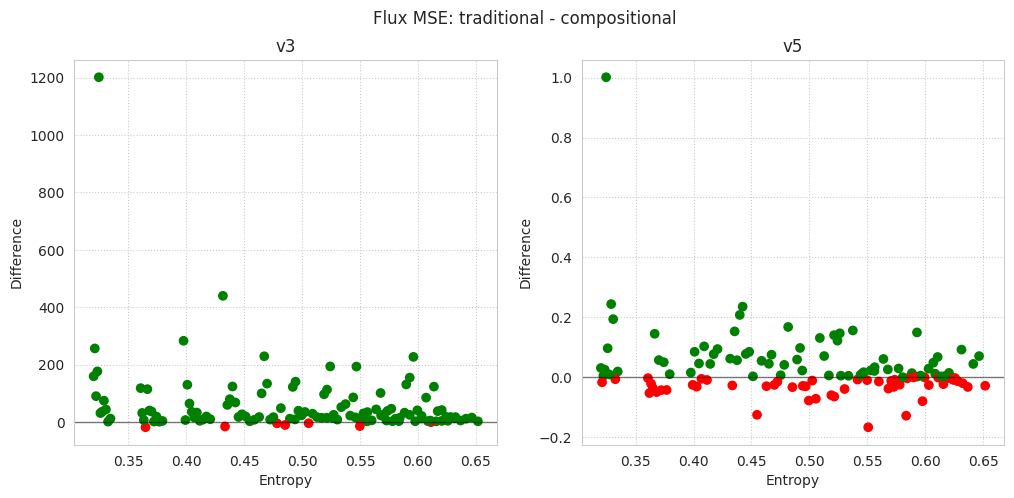

In [10]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
true_id_toy = np.load(RESULTS_DIR_TOY / "true_composition.npy")
free_fluxes_toy = jnp.load(RESULTS_DIR_TOY / "free_fluxes.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [4, 5]])
resid_clr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["clr"][:, :, [4, 5]])
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [4, 5]])

mse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
mse_clr_toy = (resid_clr_toy ** 2).mean(axis=(0, 1))
mse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

entropies_toy = jnp.load(RESULTS_DIR_TOY / "entropies.npy")

f, axes = plt.subplots(1, 2, figsize=[12, 5])
axes = axes.ravel()

for i in range(2):
    y_values = diff_flux_toy[:, i]
    colors = np.where(y_values >= 0, 'green', 'red')
    axes[i].scatter(entropies_toy, y_values, c=colors)
    axes[i].axhline(0, color='black', lw=1, alpha=0.5)
    axes[i].set(xlabel="Entropy", ylabel="Difference", title=f"v{3+2*i}")
f.suptitle("Flux MSE: traditional - compositional")
plt.show()


In [13]:
jnp.unique(free_fluxes_toy[:,0])

Array([25., 30., 35., 40., 45., 50., 55., 60., 65., 70., 75.], dtype=float64)

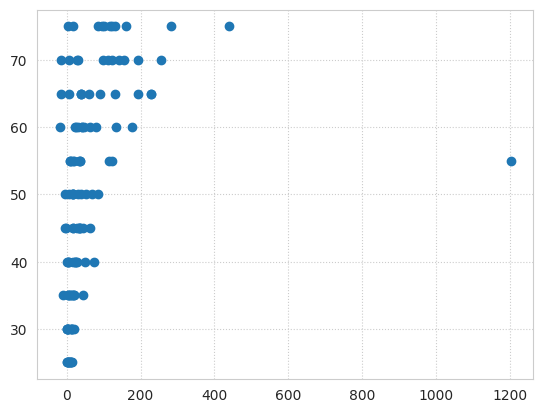

In [18]:
# v3_range = jnp.unique(free_fluxes_toy[:,0])
plt.scatter(diff_flux_toy[:,0], free_fluxes_toy[:,0])

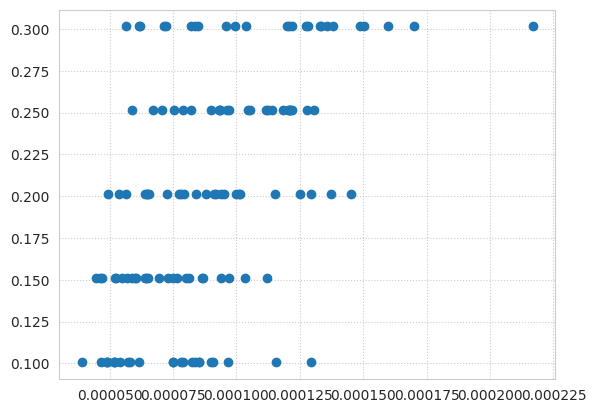

In [64]:
plt.scatter(diff_flux_tca[:,1], free_fluxes_tca[:,1])

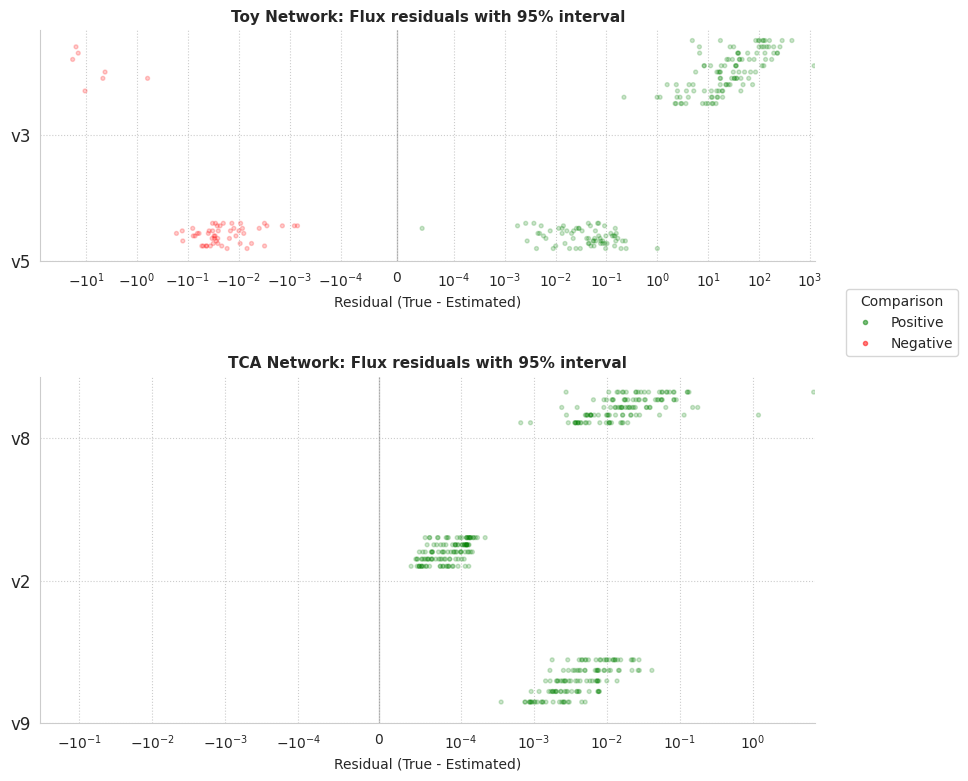

In [87]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.4})

def draw_scatter_ordered(ax, diff_data, flux_val, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (diff_data[i], pos + flux_val[i])
        ]
        for data, y_pos in data_pairs:            
            ax.scatter(data, y_pos, color=np.where(data >= 0, 'green', 'red'), s=8, alpha=0.20)
            
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=12)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_ordered(ax1, 
                    [diff_flux_toy[:, 0], diff_flux_toy[:, 1]], 
                    [free_fluxes_toy[:, 0]/100, free_fluxes_toy[:, 1]/100], 
                    ["v3", "v5"])
ax1.set_title("Toy Network: Flux residuals with 95% interval", fontweight='bold', fontsize=11)
ax1.set_xscale("symlog", linthresh=1e-4)
ax1.set_xlabel("Residual (True - Estimated)")


draw_scatter_ordered(ax2, 
                    [diff_flux_tca[:, 0], diff_flux_tca[:, 1], diff_flux_tca[:, 2]], 
                    [free_fluxes_tca[:, 0], free_fluxes_tca[:, 1], free_fluxes_tca[:, 2]], 
                    ["v8","v2", "v9"])
ax2.set_title("TCA Network: Flux residuals with 95% interval", fontweight='bold', fontsize=11)
ax2.set_xlabel("Residual (True - Estimated)")
ax2.set_xscale("symlog", linthresh=1e-4)

# Custom legend
custom_marker = [
    Line2D([0], [0], color="green", marker="o", linestyle="", markersize=3, alpha = 0.5),
    Line2D([0], [0], color="red", marker="o", linestyle="", markersize=3, alpha = 0.5),
]
fig.legend(custom_marker, ["Positive", "Negative"], fontsize=10, loc="outside right upper", title='Comparison', bbox_to_anchor=(1.05,0.6))


plt.show()

In [ ]:

# Render TCA Cycle
draw_scatter_ordered(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"])
ax2.set_title("TCA Cycle: Flux residuals with 95% interval", fontweight='bold', fontsize=11)
ax2.set_ylabel("Residual (True - Estimated)")

# Unified Legend
# ax1.legend(loc='upper right', frameon=False, bbox_to_anchor=(1.1, 1.2), ncol=2)

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha = 0.15),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha = 0.15),
]
fig.legend(custom_marker, ["Traditional", "95% interval", "Compositional", "95% interval"], fontsize=10, ncol=4, loc="outside lower center") #bbox_to_anchor=(1.1,0.6)

plt.show()